In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:")
print(df.isnull().sum())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


\nMissing values:
House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64


In [3]:
X = df.drop(columns=["Price", "House_ID"], errors="ignore")
y = df["Price"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target: Price")

Numerical features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']
Target: Price


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 12020
Testing records: 3005


In [5]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000)
}

trained_models = {}

for name, regressor in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name, "trained successfully.")

Linear Regression trained successfully.
Ridge Regression trained successfully.
Lasso Regression trained successfully.


In [7]:
predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Linear_Regression": predictions["Linear Regression"],
    "Ridge_Regression": predictions["Ridge Regression"],
    "Lasso_Regression": predictions["Lasso Regression"]
})

display(comparison.head(10))

,Actual_Price,Linear_Regression,Ridge_Regression,Lasso_Regression
0,277576,312409.772014,312460.765514,312410.196705
1,312901,355331.982107,354959.532330,355332.551998
2,360400,389929.651620,389967.477136,389929.590709
3,603911,590712.191136,590673.786569,590711.867769
4,442974,450141.693683,450221.512053,450142.185803
5,155028,149223.608509,149613.879759,149224.486668
6,431076,411598.291090,411671.885274,411599.250979
7,362047,422606.800712,422653.370409,422606.105665
8,429965,412029.303799,411910.554329,412029.245014
9,415699,409687.791562,409596.736247,409687.629434


In [8]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,30119.0358,1.774068e+09,42119.6827,0.8965
1,Ridge Regression,30121.6842,1.774496e+09,42124.7684,0.8965
2,Lasso Regression,30119.0439,1.774068e+09,42119.6910,0.8965


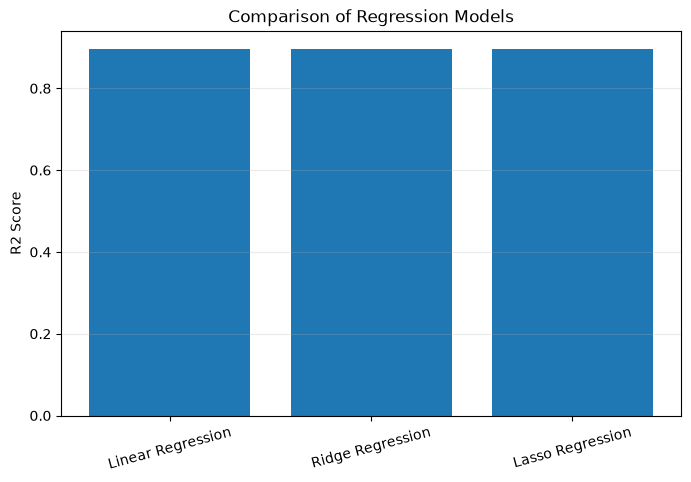

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.ylabel("R2 Score")
plt.title("Comparison of Regression Models")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.25)
plt.show()

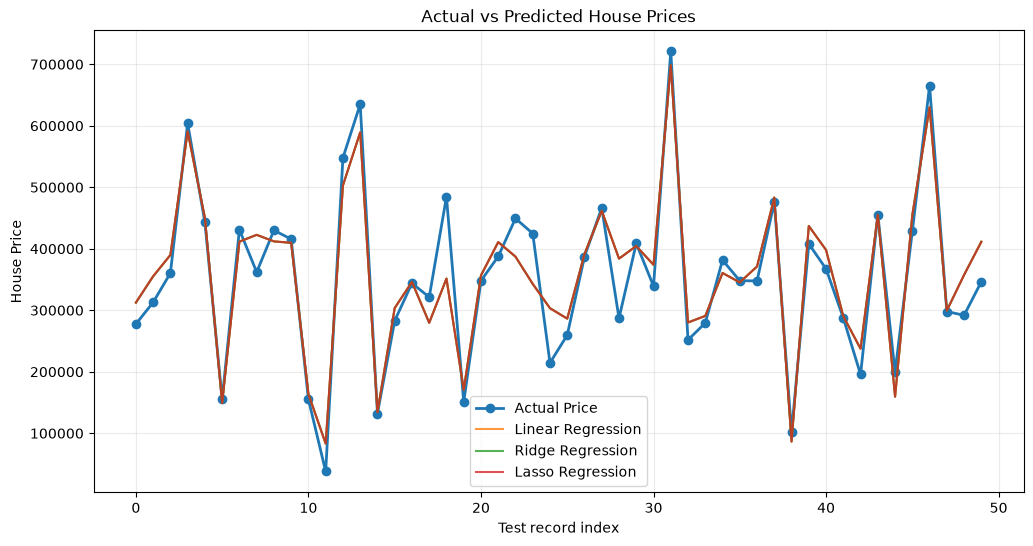

In [10]:
sample_size = min(50, len(y_test))
sample_actual = y_test.iloc[:sample_size].to_numpy()

plt.figure(figsize=(12, 6))
plt.plot(sample_actual, label="Actual Price", marker="o", linewidth=2)

for name, y_pred in predictions.items():
    plt.plot(y_pred[:sample_size], label=name, alpha=0.8)

plt.xlabel("Test record index")
plt.ylabel("House Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [11]:
coefficient_data = {}

for name, pipeline in trained_models.items():
    regressor = pipeline.named_steps["regressor"]
    coefficient_data[name] = regressor.coef_

feature_names = trained_models["Linear Regression"].named_steps[
    "preprocessor"
].get_feature_names_out()

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Linear": coefficient_data["Linear Regression"],
    "Ridge": coefficient_data["Ridge Regression"],
    "Lasso": coefficient_data["Lasso Regression"]
})

display(coef_df.head(15))

print("Number of zero coefficients in Lasso:",
      np.sum(np.isclose(coefficient_data["Lasso Regression"], 0)))

,Feature,Linear,Ridge,Lasso
0,num__Area_sqft,103303.182269,103292.264456,103303.165419
1,num__Bedrooms,15228.881808,15226.778809,15228.865750
2,num__Bathrooms,5072.213569,5071.880268,5072.195823
3,num__Floors,-590.223070,-586.260426,-590.207115
4,num__Year_Built,6486.602225,6486.898240,6486.585180
5,num__Garage_Count,5490.544249,5489.706509,5490.540019
6,num__Lot_Size_sqft,6053.836131,6055.616562,6053.826273
7,num__Distance_to_City_Center_km,-8250.344927,-8247.384061,-8250.337068
8,num__Crime_Rate_Index,-6519.512965,-6520.061680,-6519.500722
9,num__School_Rating,6661.118565,6658.687321,6661.105942


Number of zero coefficients in Lasso: 1


In [12]:
new_house = X.iloc[[0]].copy()

for name, model in trained_models.items():
    predicted_price = model.predict(new_house)[0]
    print(f"{name}: {predicted_price:,.2f}")

Linear Regression: 265,172.90
Ridge Regression: 265,225.86
Lasso Regression: 265,173.26
